# ¿Con cuánta lluvia de 6 h se emitieron las declaratorias asociadas a CT?

Para cada declaratoria (emergencia, desastre o contingencia) asociada a un ciclón tropical se obtiene la lluvia de 6 h de MSWEP V3 que hubo en el municipio mientras el CT estaba activo, y se mide **cuántos mm está por arriba o por debajo** de los percentiles locales de 6 h ya calculados (P75, P90, P95, P99, P99.9 en `mswep_v3_6h_percentiles_may_nov.nc`).

El cálculo está en `scripts/declaratorias_6h.py`; este notebook lo ejecuta (opcional) y explora las salidas de `outputs/diagnostics/declaratorias_6h/`.

- **paso**: declaratoria × hora T (00/06/12/18 UTC) con un CT activo; P(T) = acumulado en (T−6 h, T].
- **P_evento**: lluvia de 6 h de la declaratoria = máximo sobre los píxeles del municipio y los pasos.
- **dif_Pxx** = P_evento − Pxx del mismo píxel (mm (6 h)⁻¹). Negativo: la declaratoria se emitió con lluvia menor que ese percentil.
- **P_min** (municipio): la menor P_evento entre sus declaratorias, y su `dif_min_Pxx`.
- **P_min_decl** (píxel): mínimo, entre declaratorias, del máximo de 6 h en ese píxel; `P_min_menos_Pxx` = P_min_decl − Pxx.

## 1. Rutas y ejecución

In [12]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts"))

from declaratorias_6h import Config, run

OUT = REPO / "outputs/diagnostics/declaratorias_6h"
FIG = REPO / "outputs/figures/declaratorias_6h"
FIG.mkdir(parents=True, exist_ok=True)

In [13]:
# RUN = True recalcula todo (lee D:/MSWEP_V316_6H). False solo lee las salidas.
RUN = not (OUT / "declaratorias_ct_eventos.csv").exists()

cfg = Config(
    solo_lluvia=False,            # True: solo declaratorias que mencionan lluvia/inundación/remoción
    dias_antes=0, dias_despues=0, # tolerancia en días alrededor de [Fecha Inicio, Fecha Fin]; 0 = artículo
    max_dist_km=None,             # p. ej. 1000 para descartar CT lejanos
    require_inside_rocloud=False, # True: municipio dentro del radio ROCLOUD del cuadrante
)

if RUN:
    res = run(cfg)

## 2. Lectura de salidas

In [14]:
pasos = pd.read_csv(OUT / "declaratorias_ct_pasos.csv", parse_dates=["time"], dtype={"CVEGEO": str})
eventos = pd.read_csv(OUT / "declaratorias_ct_eventos.csv", parse_dates=["t_pico", "fecha_inicio", "fecha_fin"],
                      dtype={"CVEGEO": str})
mun_tab = pd.read_csv(OUT / "declaratorias_ct_municipios.csv", dtype={"CVEGEO": str})
pix = xr.open_dataset(OUT / "declaratorias_ct_pixel_min.nc")

gdf_mun = gpd.read_file(cfg.mun_shp, encoding=cfg.shp_encoding)
gdf_mun["CVEGEO"] = gdf_mun["CVEGEO"].astype(str).str.zfill(5)
mun = gdf_mun[["CVEGEO", "geometry"]].merge(mun_tab.drop(columns=["NOMGEO", "NOM_ENT"], errors="ignore"),
                                             on="CVEGEO", how="left")
estados = gdf_mun.dissolve(by="CVE_ENT")

# Percentiles disponibles en el archivo (P75, P90, P95, P99, P99_9)
LABELS = [c.replace("dif_", "") for c in eventos.columns if c.startswith("dif_")]

# Percentiles a comparar en figuras (máximo 3 series). El archivo actual tiene P75, no P70:
# para usar P70 hay que recalcular percentiles_6h.py con qs=(0.70, ...) y volver a correr el script.
REF = [l for l in ("P70", "P75", "P90", "P95") if l in LABELS][-3:]
REF_MAPA = "P95"

ev = eventos[eventos["P_evento"].notna()].copy()
print(f"Declaratorias con datos: {len(ev):,} de {len(eventos):,} | municipios: {(mun['n_decl'] > 0).sum():,}")
print(f"Percentiles en el archivo: {LABELS} | comparados: {REF}")

Declaratorias con datos: 10,437 de 10,437 | municipios: 1,712
Percentiles en el archivo: ['P75', 'P90', 'P95', 'P99', 'P99_9'] | comparados: ['P75', 'P90', 'P95']


## 3. ¿Con cuánta lluvia se emitieron y qué tan lejos están de los percentiles?

`dif` en mm (6 h)⁻¹, evaluado en el píxel del máximo del municipio.

In [15]:
def tabla_dif(df):
    return pd.DataFrame({
        "Pxx en el píxel (mediana)": [df[f"{l}_pixel_max"].median() for l in LABELS],
        "dif mín": [df[f"dif_{l}"].min() for l in LABELS],
        "dif P10": [df[f"dif_{l}"].quantile(0.10) for l in LABELS],
        "dif mediana": [df[f"dif_{l}"].median() for l in LABELS],
        "% declaratorias bajo Pxx": [100 * (df[f"dif_{l}"] < 0).mean() for l in LABELS],
    }, index=LABELS).astype(float).round(1)

print(f"P_evento (mm/6 h): mín {ev['P_evento'].min():.1f} | P10 {ev['P_evento'].quantile(0.1):.1f} | "
      f"mediana {ev['P_evento'].median():.1f}")
tabla_dif(ev)

P_evento (mm/6 h): mín 0.0 | P10 0.9 | mediana 45.9


,Pxx en el píxel (mediana),dif mín,dif P10,dif mediana,% declaratorias bajo Pxx
P75,10.8,-20.5,-7.7,34.7,22.4
P90,21.2,-35.2,-15.7,24.0,29.6
P95,30.2,-67.4,-23.4,15.1,36.1
P99,53.4,-109.2,-47.7,-7.6,57.5
P99_9,92.7,-184.6,-93.2,-42.3,87.1


In [16]:
# % de declaratorias emitidas con lluvia menor que cada percentil, por grupo
grupos = {
    "todas": ev,
    "mencionan lluvia": ev[ev["menciona_lluvia"]],
    "no mencionan lluvia": ev[~ev["menciona_lluvia"]],
    "Emergencia": ev[ev["Tipo Declaratoria"].eq("Emergencia")],
    "Desastre": ev[ev["Tipo Declaratoria"].eq("Desastre")],
}
pd.DataFrame({g: {"n": len(d), **{f"% < {l}": round(100 * (d[f"dif_{l}"] < 0).mean(), 1) for l in LABELS}}
              for g, d in grupos.items()}).T

,n,% < P75,% < P90,% < P95,% < P99,% < P99_9
todas,10437.0,22.4,29.6,36.1,57.5,87.1
mencionan lluvia,2374.0,5.1,8.2,12.0,32.1,77.3
no mencionan lluvia,8063.0,27.5,35.9,43.2,65.0,90.0
Emergencia,5794.0,37.5,46.7,53.2,71.5,91.9
Desastre,4388.0,3.8,8.5,15.0,41.0,82.2


## 4. Distribución de la lluvia y de la distancia a los percentiles

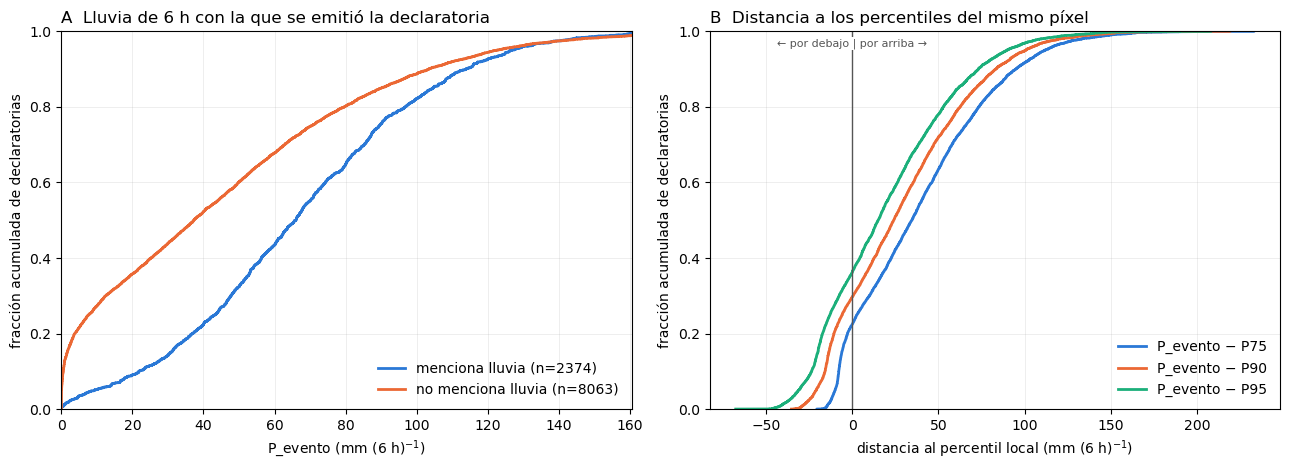

In [17]:
C3 = ["#2a78d6", "#eb6834", "#1baf7a"]          # identidad de serie, orden fijo
C_LLUVIA, C_OTRAS = C3[0], C3[1]

def ecdf(ax, x, **kw):
    x = np.sort(np.asarray(x)[np.isfinite(x)])
    ax.step(x, np.arange(1, x.size + 1) / x.size, where="post", lw=2, **kw)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.8))

for mask, color, lab in [(ev["menciona_lluvia"], C_LLUVIA, "menciona lluvia"),
                         (~ev["menciona_lluvia"], C_OTRAS, "no menciona lluvia")]:
    ecdf(ax0, ev.loc[mask, "P_evento"], color=color, label=f"{lab} (n={mask.sum()})")
ax0.set_xlabel("P_evento (mm (6 h)$^{-1}$)")
ax0.set_xlim(0, np.nanpercentile(ev["P_evento"], 99))
ax0.set_title("A  Lluvia de 6 h con la que se emitió la declaratoria", loc="left")

for lab, color in zip(REF, C3):
    ecdf(ax1, ev[f"dif_{lab}"], color=color, label=f"P_evento − {lab}")
ax1.axvline(0, color="#555555", lw=1)
ax1.annotate("← por debajo | por arriba →", (0, 0.96), xytext=(0, 0), textcoords="offset points", ha="center",
             fontsize=8, color="#555555", bbox=dict(fc="white", ec="none", pad=1))
ax1.set_xlabel("distancia al percentil local (mm (6 h)$^{-1}$)")
ax1.set_title("B  Distancia a los percentiles del mismo píxel", loc="left")

for ax in (ax0, ax1):
    ax.set_ylabel("fracción acumulada de declaratorias")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3, lw=0.5)
    ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig(FIG / "fig_P_evento_y_distancia_percentiles.png", dpi=300, bbox_inches="tight")

## 5. Mapa municipal: lluvia mínima con la que hubo declaratoria y su distancia al percentil

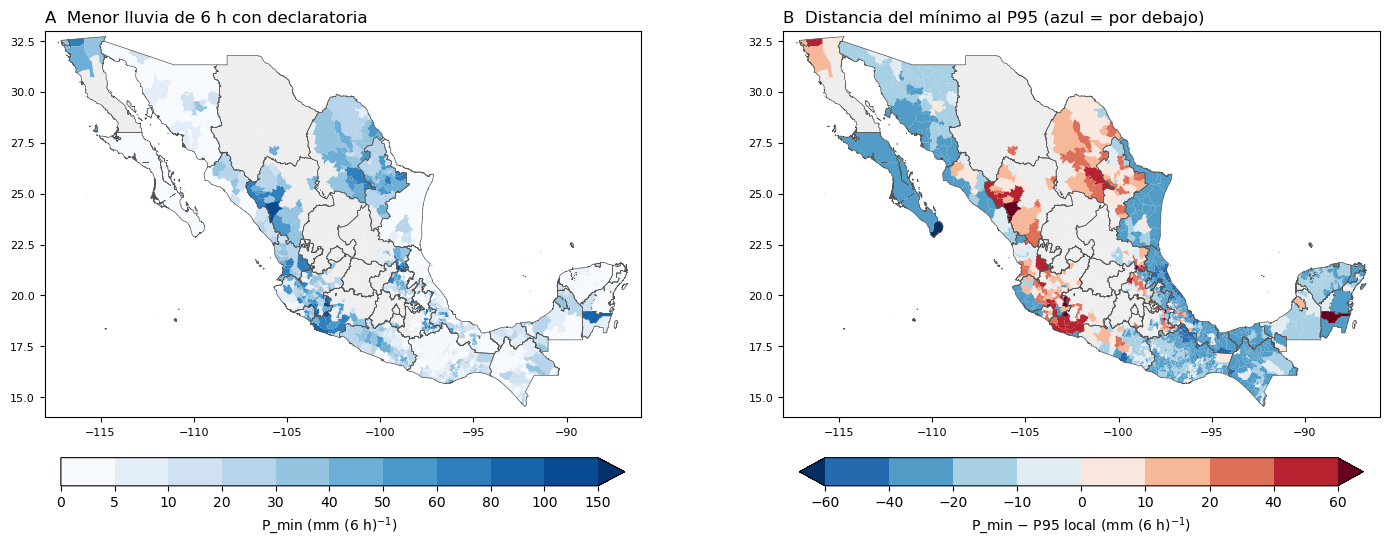

In [18]:
EXT = dict(xlim=(-118, -86), ylim=(14, 33))

B_P = [0, 5, 10, 20, 30, 40, 50, 60, 80, 100, 150]
CMAP_P = plt.cm.Blues
NORM_P = BoundaryNorm(B_P, CMAP_P.N, extend="max")

B_D = [-60, -40, -20, -10, 0, 10, 20, 40, 60]        # simétrico: 4 clases bajo y 4 sobre el percentil
CMAP_D = plt.cm.RdBu_r
NORM_D = BoundaryNorm(B_D, CMAP_D.N, extend="both")

def base(ax):
    gdf_mun.plot(ax=ax, color="#eeeeee", edgecolor="none")
    estados.boundary.plot(ax=ax, color="#555555", lw=0.5, zorder=3)
    ax.set(**EXT, aspect="equal")
    ax.tick_params(labelsize=8)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 5.6))
base(ax0); base(ax1)
con = mun[mun["n_decl"] > 0]

con.plot(ax=ax0, column="P_min", cmap=CMAP_P, norm=NORM_P, edgecolor="none", zorder=2)
fig.colorbar(plt.cm.ScalarMappable(norm=NORM_P, cmap=CMAP_P), ax=ax0, orientation="horizontal",
             shrink=0.8, pad=0.08, ticks=B_P, label="P_min (mm (6 h)$^{-1}$)")
ax0.set_title("A  Menor lluvia de 6 h con declaratoria", loc="left")

con.plot(ax=ax1, column=f"dif_min_{REF_MAPA}", cmap=CMAP_D, norm=NORM_D, edgecolor="none", zorder=2)
fig.colorbar(plt.cm.ScalarMappable(norm=NORM_D, cmap=CMAP_D), ax=ax1, orientation="horizontal",
             shrink=0.8, pad=0.08, ticks=B_D, label=f"P_min − {REF_MAPA} local (mm (6 h)$^{{-1}}$)")
ax1.set_title(f"B  Distancia del mínimo al {REF_MAPA} (azul = por debajo)", loc="left")

fig.tight_layout()
fig.savefig(FIG / f"fig_mapa_municipal_P_min_{REF_MAPA}.png", dpi=300, bbox_inches="tight")

## 6. Mapa por píxel

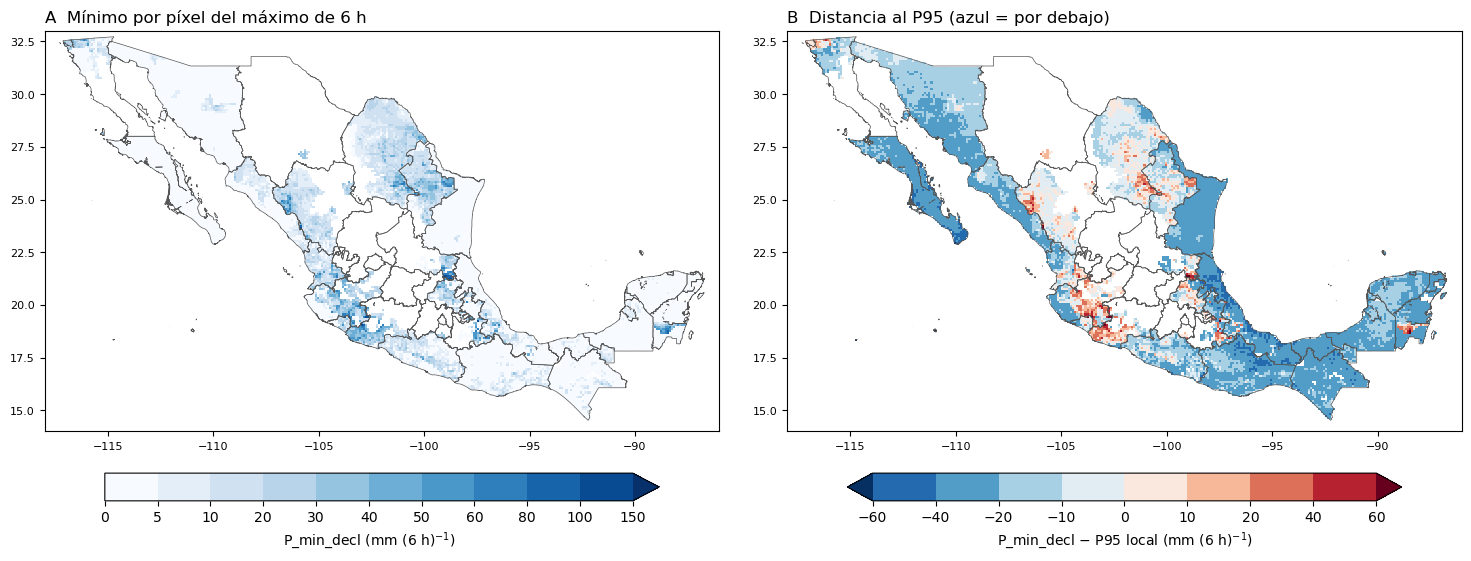

In [19]:
ok = pix["n_decl"] > 0

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 5.6))

m0 = ax0.pcolormesh(pix["lon"], pix["lat"], pix["P_min_decl"].where(ok), cmap=CMAP_P, norm=NORM_P, shading="auto")
fig.colorbar(m0, ax=ax0, orientation="horizontal", shrink=0.8, pad=0.08, ticks=B_P,
             label="P_min_decl (mm (6 h)$^{-1}$)")
ax0.set_title("A  Mínimo por píxel del máximo de 6 h", loc="left")

m1 = ax1.pcolormesh(pix["lon"], pix["lat"], pix[f"P_min_menos_{REF_MAPA}"].where(ok), cmap=CMAP_D, norm=NORM_D,
                    shading="auto")
fig.colorbar(m1, ax=ax1, orientation="horizontal", shrink=0.8, pad=0.08, ticks=B_D,
             label=f"P_min_decl − {REF_MAPA} local (mm (6 h)$^{{-1}}$)")
ax1.set_title(f"B  Distancia al {REF_MAPA} (azul = por debajo)", loc="left")

for ax in (ax0, ax1):
    estados.boundary.plot(ax=ax, color="#555555", lw=0.5)
    ax.set(**EXT, aspect="equal")
    ax.tick_params(labelsize=8)

fig.tight_layout()
fig.savefig(FIG / f"fig_mapa_pixel_P_min_{REF_MAPA}.png", dpi=300, bbox_inches="tight")

## 7. ¿El CT estaba cerca?

La asociación es solo temporal (como en el artículo). Si las declaratorias por debajo del percentil se concentran lejos del CT o fuera de ROCLOUD, probablemente esa lluvia no es la que motivó la declaratoria.

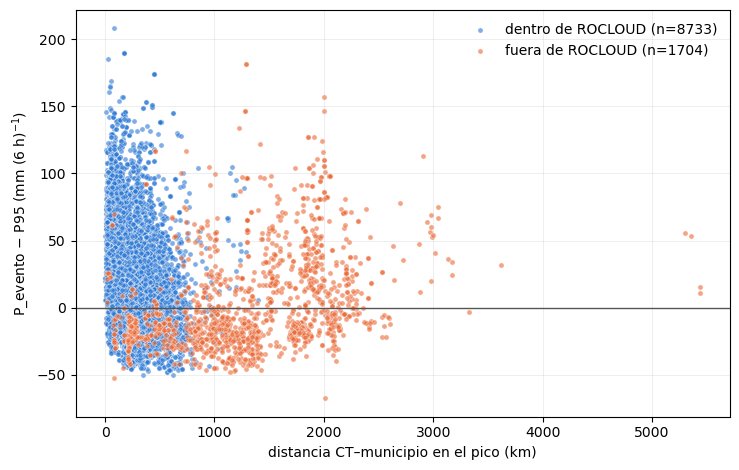

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for mask, color, lab in [(ev["dentro_rocloud_pico"] == True, C3[0], "dentro de ROCLOUD"),
                         (ev["dentro_rocloud_pico"] != True, C3[1], "fuera de ROCLOUD")]:
    ax.scatter(ev.loc[mask, "dist_pico_km"], ev.loc[mask, f"dif_{REF_MAPA}"], s=14, color=color, alpha=0.6,
               edgecolor="white", linewidth=0.4, label=f"{lab} (n={mask.sum()})")
ax.axhline(0, color="#555555", lw=1)
ax.set_xlabel("distancia CT–municipio en el pico (km)")
ax.set_ylabel(f"P_evento − {REF_MAPA} (mm (6 h)$^{{-1}}$)")
ax.grid(alpha=0.3, lw=0.5)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / f"fig_dif_{REF_MAPA}_vs_distancia.png", dpi=300, bbox_inches="tight")

## 8. Municipios con la menor lluvia asociada a declaratoria (revisión manual)

In [21]:
cols = (["CVEGEO", "NOMGEO", "NOM_ENT", "n_decl", "n_pix", "P_min"]
        + [f"{l}_pixel_min" for l in REF] + [f"dif_min_{l}" for l in REF]
        + ["lluvia_min", "obs_min", "CT_min", "dist_min_km", "t_pico_min"])
mun_tab[mun_tab["n_decl"] > 0].sort_values("P_min")[cols].head(25).round(1)

,CVEGEO,NOMGEO,NOM_ENT,n_decl,n_pix,P_min,P75_pixel_min,P90_pixel_min,P95_pixel_min,dif_min_P75,dif_min_P90,dif_min_P95,lluvia_min,obs_min,CT_min,dist_min_km,t_pico_min
1465,20383,Santa Cruz Tayata,Oaxaca,2,0.0,0.0,6.7,12.7,18.1,-6.7,-12.7,-18.1,False,Tormenta tropical Rosa. No se especifican los ...,EP192000,479.7,2000-11-07 00:00:00
481,13016,Cuautepec de Hinojosa,Hidalgo,8,4.0,0.0,5.1,8.6,10.7,-5.1,-8.6,-10.7,False,"Depresion Tropical ""Stan""",AL252005,1309.8,2005-10-21 00:00:00
483,13014,Calnali,Hidalgo,7,2.0,0.0,11.0,22.6,33.5,-11.0,-22.6,-33.5,False,"Depresion Tropical ""Stan""",AL252005,1345.1,2005-10-21 00:00:00
489,13079,Xochicoatlán,Hidalgo,6,1.0,0.0,12.3,25.7,37.2,-12.3,-25.7,-37.2,False,"Depresion Tropical ""Stan""",AL252005,1354.7,2005-10-21 00:00:00
1997,28025,Miguel Alemán,Tamaulipas,5,6.0,0.0,8.9,17.5,28.0,-8.9,-17.5,-28.0,False,Tormenta tropical Barry,AL052000,663.1,2000-08-14 00:00:00
1456,20370,Santa Catarina Tayata,Oaxaca,2,1.0,0.0,6.7,12.7,18.1,-6.7,-12.7,-18.1,False,Tormenta tropical Rosa. No se especifican los ...,EP192000,476.7,2000-11-07 00:00:00
1457,20381,Santa Cruz Tacache de Mina,Oaxaca,3,0.0,0.0,8.1,15.0,19.8,-8.1,-15.0,-19.8,False,Tormenta tropical Rosa. No se especifican los ...,EP192000,516.6,2000-11-07 00:00:00
1459,20373,Santa Catarina Zapoquila,Oaxaca,2,0.0,0.0,8.1,14.9,19.6,-8.1,-14.9,-19.6,False,Tormenta tropical Rosa. No se especifican los ...,EP192000,550.7,2000-11-07 00:00:00
1460,20374,Santa Cruz Acatepec,Oaxaca,4,0.0,0.0,11.6,22.7,33.1,-11.6,-22.7,-33.1,False,Tormenta tropical Rosa. No se especifican los ...,EP192000,584.7,2000-11-07 00:00:00
1463,20376,Santa Cruz de Bravo,Oaxaca,2,0.0,0.0,5.6,9.6,12.5,-5.6,-9.6,-12.5,False,Tormenta tropical Rosa. No se especifican los ...,EP192000,488.9,2000-11-07 00:00:00


## 9. Serie de una declaratoria

In [25]:
ev["id_decl"]

0            0
1            1
2            2
3            3
4            4
         ...  
10432    10538
10433    10539
10434    10540
10435    10541
10436    10542
Name: id_decl, Length: 10437, dtype: int64

,time,CT,dentro_rocloud,dist_km,P_max,P_media,dif_P75,dif_P90,dif_P95
23533,2007-08-18 00:00:00,AL052007,False,1704.3,0.0,0.0,-4.3,-7.4,-10.1
23534,2007-08-18 06:00:00,AL052007,False,1755.4,0.0,0.0,-4.3,-7.4,-10.1
23535,2007-08-18 12:00:00,AL052007,False,1788.4,0.0,0.0,-4.3,-7.4,-10.1
23536,2007-08-18 18:00:00,AL052007,False,1820.6,0.0,0.0,-4.3,-7.4,-10.1


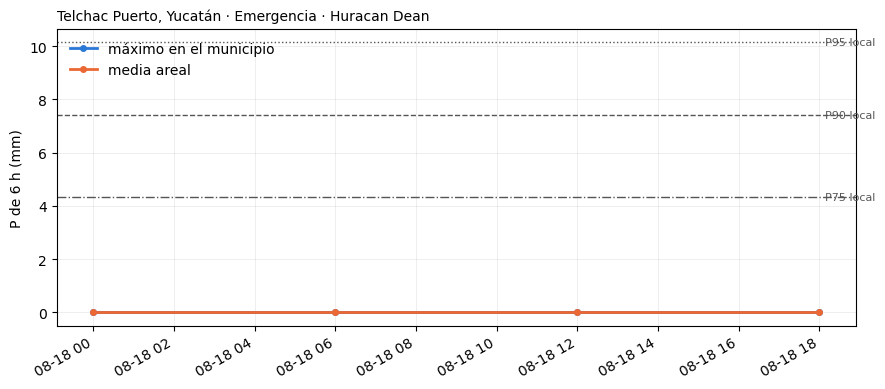

In [32]:
# Cambiar ID para revisar otra declaratoria (columna id_decl de eventos)
ID = ev.sort_values("P_evento").iloc[104]["id_decl"]

e = eventos.set_index("id_decl").loc[ID]
s = pasos[pasos["id_decl"].eq(ID)].sort_values("time")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s["time"], s["P_max"], color=C3[0], lw=2, marker="o", ms=4, label="máximo en el municipio")
ax.plot(s["time"], s["P_media"], color=C3[1], lw=2, marker="o", ms=4, label="media areal")
for lab, ls in zip(REF, ["-.", "--", ":"]):
    ax.axhline(e[f"{lab}_pixel_max"], color="#555555", lw=1, ls=ls)
    ax.annotate(f"{lab} local", (s["time"].iloc[-1], e[f"{lab}_pixel_max"]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color="#555555")
ax.set_ylabel("P de 6 h (mm)")
ax.set_title(f"{e['Municipio']}, {e['Estado']} · {e['Tipo Declaratoria']} · {e['Observaciones']}", loc="left", fontsize=10)
ax.grid(alpha=0.3, lw=0.5)
ax.legend(frameon=False, loc="upper left")
fig.autofmt_xdate()
fig.tight_layout()
num = ["dist_km", "P_max", "P_media"] + [f"dif_{l}" for l in REF]
s[["time", "CT", "dentro_rocloud"] + num].round(dict.fromkeys(num, 1))

In [30]:
s

,id_decl,CVEGEO,time,CT,lat_ct,lon_ct,MWS,Rp,dist_km,R_quad_km,...,frac_area_ge_P95,P99_pixel_max,dif_P99,frac_area_ge_P99,P99_9_pixel_max,dif_P99_9,frac_area_ge_P99_9,lat_pmax,lon_pmax,con_datos
4761,489,31061,2004-09-12 00:00:00,AL092004,18.2,-79.6,268.2,800.12,965.526,681.46,...,0.0,29.084,-29.084,0.0,56.847,-56.847,0.0,21.55,-88.15,True
4762,489,31061,2004-09-12 06:00:00,AL092004,18.4,-80.4,249.7,632.35,879.374,319.86,...,0.0,29.084,-29.084,0.0,56.847,-56.847,0.0,21.55,-88.15,True
4763,489,31061,2004-09-12 12:00:00,AL092004,18.8,-81.2,249.7,566.77,784.241,276.66,...,0.0,29.084,-29.084,0.0,56.847,-56.847,0.0,21.55,-88.15,True
4764,489,31061,2004-09-12 18:00:00,AL092004,19.1,-82.1,240.5,668.78,684.207,445.60,...,0.0,29.084,-29.084,0.0,56.847,-56.847,0.0,21.55,-88.15,True


## 10. Sensibilidad a los criterios

La lluvia asignada depende de las fechas de la declaratoria. Ejemplo 2020: Cozumel con Delta da 0.8 mm con las fechas originales (5–6 oct) y 101 mm agregando un día (entrada a tierra el 7 oct). Cada variante se guarda en su carpeta; cada corrida lee los 26 años de MSWEP.

In [23]:
SENS = False   # True para correr todas las variantes

variantes = {
    "articulo":            dict(),
    "lluvia":              dict(solo_lluvia=True),
    "lluvia_+1d":          dict(solo_lluvia=True, dias_despues=1),
    "lluvia_±1d":          dict(solo_lluvia=True, dias_antes=1, dias_despues=1),
    "lluvia_±1d_rocloud":  dict(solo_lluvia=True, dias_antes=1, dias_despues=1, require_inside_rocloud=True),
}

def out_dir(nombre):
    return REPO / "outputs/diagnostics" / f"declaratorias_6h_{nombre}"

if SENS:
    for nombre, kw in variantes.items():
        run(Config(out_dir=str(out_dir(nombre)), **kw))

filas = {}
for nombre in variantes:
    f = out_dir(nombre) / "declaratorias_ct_eventos.csv"
    if f.exists():
        d = pd.read_csv(f)
        d = d[d["P_evento"].notna()]
        filas[nombre] = {"n": len(d), "P_evento mín": d["P_evento"].min(), "P_evento P10": d["P_evento"].quantile(0.1),
                         **{f"% < {l}": 100 * (d[f"dif_{l}"] < 0).mean() for l in LABELS}}
pd.DataFrame(filas).T.astype(float).round(1)

""
